# Customer Churn Prediction – Analysis and Model Building

This notebook explores the Telco customer dataset, prepares the features, compares Logistic Regression and Decision Tree, tunes the models, and saves the selected pipeline.

## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, RocCurveDisplay)
import joblib
from pathlib import Path

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')

## 2. Load dataset



In [2]:
df = pd.read_csv('../dataset/customer_churn.csv')
print('Shape:', df.shape)
display(df.head())

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Understand the data

In [3]:
df.info()
display(df.describe(include='all').T)
print('Duplicate rows:', df.duplicated().sum())
print('Missing values before TotalCharges conversion:')
display(df.isna().sum().sort_values(ascending=False).head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Duplicate rows: 0
Missing values before TotalCharges conversion:


customerID         0
gender             0
SeniorCitizen      0
Partner            0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
OnlineSecurity     0
dtype: int64

## 4. Clean data types

`TotalCharges` is represented as text in this dataset. Convert it to numeric; blank strings become `NaN` and will be imputed inside the model pipeline.

In [4]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Missing values after conversion:')
display(df.isna().sum().sort_values(ascending=False).head())
print('Target counts:')
display(df['Churn'].value_counts())
display((df['Churn'].value_counts(normalize=True) * 100).round(2))

Missing values after conversion:


TotalCharges     11
gender            0
SeniorCitizen     0
Partner           0
customerID        0
dtype: int64

Target counts:


Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

## 5. Exploratory Data Analysis (EDA)

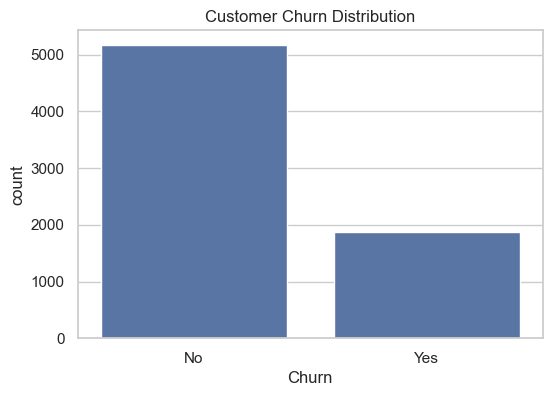

In [5]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='Churn')
plt.title('Customer Churn Distribution')
plt.show()

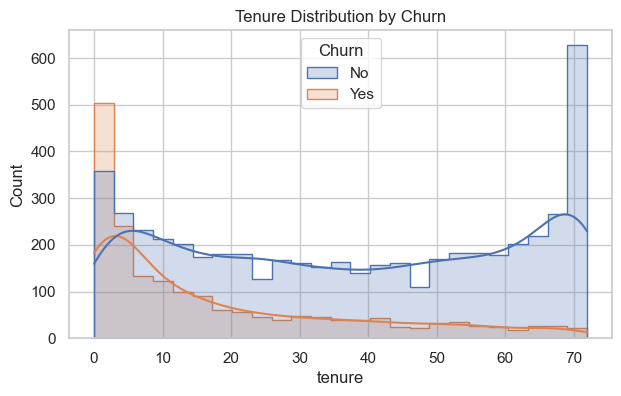

In [6]:
plt.figure(figsize=(7,4))
sns.histplot(data=df, x='tenure', hue='Churn', bins=25, kde=True, element='step')
plt.title('Tenure Distribution by Churn')
plt.show()

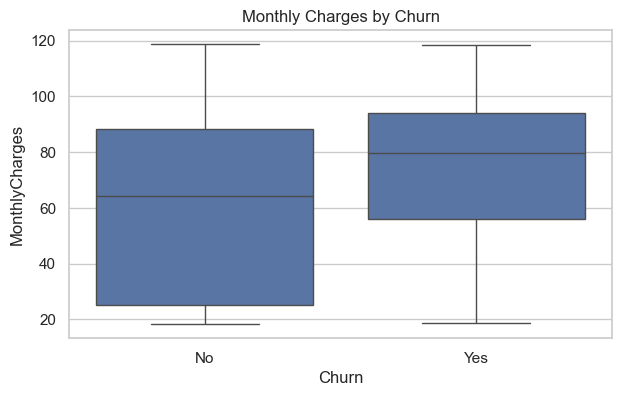

In [7]:
plt.figure(figsize=(7,4))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title('Monthly Charges by Churn')
plt.show()

<Figure size 1000x500 with 0 Axes>

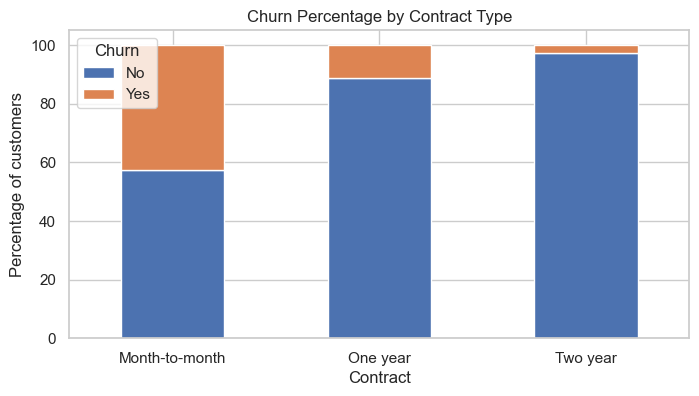

In [8]:
plt.figure(figsize=(10,5))
contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
contract_churn.plot(kind='bar', stacked=True, figsize=(8,4))
plt.ylabel('Percentage of customers')
plt.title('Churn Percentage by Contract Type')
plt.xticks(rotation=0)
plt.show()

## 6. Prepare features and target

`customerID` is removed because it is only an identifier. `Churn` is mapped to 1 for Yes and 0 for No.

In [9]:
y = df['Churn'].map({'No': 0, 'Yes': 1})
X = df.drop(columns=['Churn', 'customerID'])

categorical_features = X.select_dtypes(include=['object']).columns.tolist()
numeric_features = X.select_dtypes(exclude=['object']).columns.tolist()
print('Categorical features:', categorical_features)
print('Numeric features:', numeric_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print('Train:', X_train.shape, 'Test:', X_test.shape)

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Train: (5634, 19) Test: (1409, 19)


## 7. Build preprocessing pipelines

Numeric columns use median imputation and standardization. Categorical columns use most-frequent imputation and One-Hot Encoding. Fitting preprocessing inside a Pipeline prevents information leakage from the test set.

In [10]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

## 8. Train baseline models and compare

In [11]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight='balanced')
}

baseline_pipelines = {}
rows = []
for name, estimator in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('classifier', estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]
    baseline_pipelines[name] = pipe
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1-score': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, prob)
    })

baseline_results = pd.DataFrame(rows).sort_values('F1-score', ascending=False)
display(baseline_results)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.738112,0.504303,0.783422,0.613613,0.841298
1,Decision Tree,0.728176,0.487805,0.481283,0.484522,0.649570


## 9. Hyperparameter tuning

GridSearchCV uses recall as the scoring metric. Recall is relevant when the business wants to identify as many actual churners as possible. Check precision as well because higher recall can increase false-positive alerts.

In [12]:
param_grids = {
    'Logistic Regression': {
        'classifier__C': [0.1, 1.0, 5.0],
        'classifier__solver': ['liblinear']
    },
    'Decision Tree': {
        'classifier__max_depth': [3, 5, 8, None],
        'classifier__min_samples_split': [2, 10, 20],
        'classifier__min_samples_leaf': [1, 5, 10]
    }
}

tuned_models = {}
tuned_rows = []
for name, estimator in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('classifier', estimator)])
    search = GridSearchCV(pipe, param_grids[name], cv=5, scoring='recall', n_jobs=-1)
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    pred = search.predict(X_test)
    prob = search.predict_proba(X_test)[:, 1]
    tuned_rows.append({
        'Model': name,
        'Best CV Recall': search.best_score_,
        'Test Accuracy': accuracy_score(y_test, pred),
        'Test Precision': precision_score(y_test, pred, zero_division=0),
        'Test Recall': recall_score(y_test, pred, zero_division=0),
        'Test F1-score': f1_score(y_test, pred, zero_division=0),
        'Test ROC-AUC': roc_auc_score(y_test, prob),
        'Best Parameters': search.best_params_
    })

tuned_results = pd.DataFrame(tuned_rows)
display(tuned_results.drop(columns='Best Parameters'))
for row in tuned_rows:
    print(row['Model'], row['Best Parameters'])

,Model,Best CV Recall,Test Accuracy,Test Precision,Test Recall,Test F1-score,Test ROC-AUC
0,Logistic Regression,0.804682,0.738112,0.504303,0.783422,0.613613,0.841466
1,Decision Tree,0.784615,0.755145,0.526902,0.759358,0.622125,0.832279


Logistic Regression {'classifier__C': 1.0, 'classifier__solver': 'liblinear'}
Decision Tree {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2}


## 10. Select model and evaluate

Selected model: Logistic Regression
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.8415


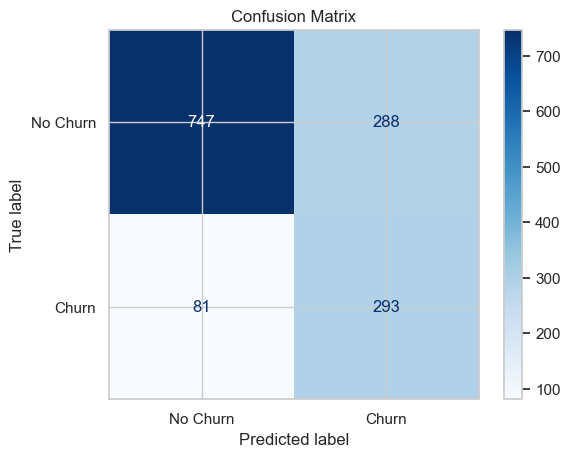

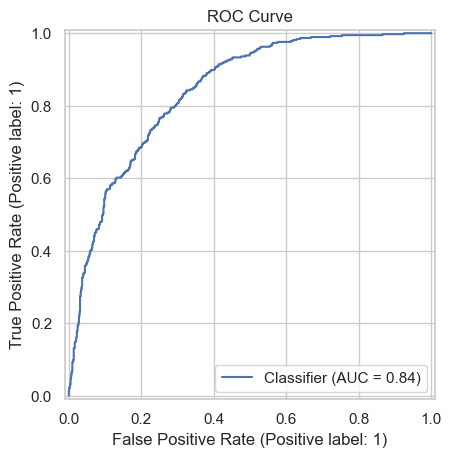

In [13]:
best_name = tuned_results.sort_values('Test Recall', ascending=False).iloc[0]['Model']
best_model = tuned_models[best_name]
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print('Selected model:', best_name)
print(classification_report(y_test, y_pred, target_names=['No Churn', 'Churn']))
print('ROC-AUC:', round(roc_auc_score(y_test, y_prob), 4))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No Churn', 'Churn'], cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title('ROC Curve')
plt.show()

## 11. Save the complete pipeline

The saved object includes the imputers, scaler, encoder, and classifier. The Flask app can therefore accept raw customer fields and apply the same preprocessing automatically.

In [14]:
Path('../models').mkdir(exist_ok=True)
joblib.dump(best_model, '../models/churn_pipeline.pkl')
print('Saved to ../models/churn_pipeline.pkl')

Saved to ../models/churn_pipeline.pkl


## 12. Business recommendations

Use model scores to prioritize human-reviewed retention outreach. For example, review customers with month-to-month contracts, short tenure, or service-support needs. Do not assume a feature causes churn merely because it is associated with churn; validate interventions with controlled experiments.